# Aula 2 — Qualidade de dados de NGS e comparação de sequências: prática em Python (Google Colab)

**Disciplina:** Introdução à Bioinformática — PPGED / IME

Este caderno refaz, **em código Python comentado**, a mesma prática que fazemos no navegador (Galaxy, BLAST, Clustal Omega, visualizador de `.ab1` e CAP3). Ele **não substitui** a prática no Galaxy: é um segundo caminho, para você ver **"por dentro"** o que cada ferramenta faz com os seus dados.

| Parte | O que você vai fazer | Ferramenta equivalente na aula |
|---|---|---|
| **A** | Ler reads de um arquivo FASTQ, decodificar o Phred Score, montar o "raio-X" da qualidade e **aparar** as reads | `fastq-dump` · FastQC · Trimmomatic |
| **B** | Construir um **mini-alinhador**, ler um arquivo **SAM** (FLAG e CIGAR) e **reproduzir o `samtools flagstat`** | Bowtie2 · SAMtools flagstat |
| **C** | Alinhar duas proteínas, entender o **E-value** com um experimento, rodar um **BLAST** pela API e marcar regiões conservadas como o Clustal | BLAST · Clustal Omega |
| **D** *(opcional)* | Abrir um arquivo Sanger **`.ab1`**, ver o cromatograma e o Phred, aparar e **montar um contig** | Visualizador de `.ab1` · CAP3 |

---

### Primeira vez no Colab? Leia isto (2 minutos)

- Um **caderno** (*notebook*) mistura **texto** (como este) e **células de código** (caixas cinzas).
- Para **executar** uma célula de código: clique nela e pressione **Shift + Enter** (ou clique no ▶ à esquerda).
- Execute as células **em ordem, de cima para baixo**. Cada uma usa o que a anterior preparou.
- Linhas que começam com `#` são **comentários**: explicações para humanos, que o computador ignora. **Leia os comentários**: eles são o material didático.
- Não tenha medo de errar: se algo der errado, use o menu **Ambiente de execução → Reiniciar e executar tudo**.
- Você **não precisa** entender cada linha. Foque no *que* cada bloco faz e no *resultado* que ele mostra.

> **Tempo estimado:** Parte A ≈ 35 min · Parte B ≈ 30 min · Parte C ≈ 25 min · Parte D (opcional) ≈ 30 min.

### Aviso importante sobre os dados

Alguns blocos baixam dados reais da internet (ENA, UniProt, Zenodo, NCBI). **Se o servidor estiver fora do ar, o caderno avisa e usa dados simulados** para você não ficar parado. Sempre confira a mensagem *"Fonte dos dados"* impressa antes dos gráficos: ela diz se você está vendo dados **reais** ou **simulados**.

## 0. Preparação do ambiente

Python sozinho sabe fazer contas e manipular texto. Para tarefas especializadas usamos **bibliotecas** (pacotes de código prontos, escritos por outras pessoas). Hoje usaremos:

| Biblioteca | Para que serve aqui |
|---|---|
| **biopython** | A "caixa de ferramentas" de bioinformática em Python: ler arquivos `.ab1`, alinhar sequências, falar com o BLAST |
| **numpy** | Contas numéricas rápidas sobre muitos números de uma vez |
| **pandas** | Tabelas (como uma planilha do Excel dentro do Python) |
| **matplotlib** | Gráficos |
| **requests** | Baixar arquivos da internet e conversar com APIs |

A célula abaixo instala o Biopython (o `%pip` manda o comando de instalação para a máquina do Colab).

In [1]:
# Instala o Biopython (leva ~20 segundos). O "-q" deixa a saída silenciosa.
%pip install -q biopython

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 41.7 MB/s eta 0:00:00


In [2]:
# ------------------------------------------------------------------
# Importa (carrega) as bibliotecas que vamos usar.
# "import X as Y" significa: carregue X e me deixe chamá-lo de Y (apelido curto).
# ------------------------------------------------------------------
import os, re, gzip, time, urllib.request, collections   # utilitários do próprio Python
import numpy as np                  # contas numéricas
import pandas as pd                 # tabelas
import matplotlib.pyplot as plt     # gráficos
import requests                     # downloads
import Bio                          # Biopython
from Bio import SeqIO, Align        # SeqIO: ler arquivos de sequência | Align: alinhar sequências
from Bio.Align import substitution_matrices   # matrizes de pontuação (BLOSUM62...)

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

# Cores usadas em todos os gráficos (as mesmas do caderno da Aula 5).
# Laranja e azul continuam distinguíveis para pessoas daltônicas.
COR_A  = "#C8611C"   # laranja
COR_B  = "#1F6FB4"   # azul
COR_NS = "#B9B2A4"   # cinza
TINTA, TINTA_SUAVE = "#14232F", "#4A5560"

plt.rcParams.update({
    "figure.dpi": 110, "font.size": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": TINTA_SUAVE, "axes.labelcolor": TINTA,
    "xtick.color": TINTA_SUAVE, "ytick.color": TINTA_SUAVE,
    "axes.grid": True, "grid.color": "#E6E1D6", "grid.linewidth": 0.8,
})


def baixar(url, nome_arquivo, tentativas=3):
    """Baixa um arquivo da internet e salva com o nome indicado.

    Se o arquivo já existir (porque você rodou a célula antes), não baixa de novo.
    Tenta algumas vezes, porque servidores públicos às vezes falham por instantes.
    """
    if os.path.exists(nome_arquivo) and os.path.getsize(nome_arquivo) > 0:
        print(f"✔ {nome_arquivo} já está aqui (não precisei baixar de novo)")
        return nome_arquivo
    for tentativa in range(1, tentativas + 1):
        try:
            resposta = requests.get(url, timeout=180)
            resposta.raise_for_status()               # gera erro se o servidor respondeu "não encontrado" etc.
            with open(nome_arquivo, "wb") as arquivo:
                arquivo.write(resposta.content)
            print(f"✔ baixado: {nome_arquivo} ({len(resposta.content) / 1e6:.2f} MB)")
            return nome_arquivo
        except Exception as erro:
            print(f"  tentativa {tentativa} falhou: {erro}")
            time.sleep(2 * tentativa)
    raise RuntimeError(f"Não consegui baixar {url}. Verifique a internet e rode a célula de novo.")


COMPLEMENTO = str.maketrans("ACGTN", "TGCAN")

def revcomp(seq):
    """Reverso-complementar de um trecho de DNA.

    O DNA tem duas fitas que se pareiam em sentidos opostos (A-T, C-G). A "outra fita"
    de ACCG é CGGT lida de trás para frente: revcomp("ACCG") = "CGGT".
    """
    return seq.translate(COMPLEMENTO)[::-1]

print("Biopython versão", Bio.__version__, "— tudo pronto! Pode seguir para a Parte A.")

Biopython versão 1.88 — tudo pronto! Pode seguir para a Parte A.


---
# PARTE A — O FASTQ por dentro: qualidade e limpeza

No Galaxy você clicou em **FastQC** e depois em **Trimmomatic**. Aqui vamos descobrir **o que essas ferramentas calculam**, escrevendo versões simples delas.

## A1. Obter algumas reads reais

A amostra da prática é a **`SRR957824`** (*E. coli* O157, projeto de investigação de surto, PRJNA215830).

O arquivo completo tem ~3 milhões de reads. Para não baixar tudo, vamos **ler em fluxo (*streaming*)** apenas as **primeiras 20.000 reads** do arquivo `R1`, a partir do **ENA** (o espelho europeu do SRA). O ENA tem uma API que informa o endereço exato do arquivo FASTQ de cada *run*.

> **Cuidado:** as primeiras 20 mil reads **não são uma amostra aleatória** do arquivo (vêm do começo da corrida). Servem muito bem para aprender, mas não para tirar conclusões biológicas sobre a amostra inteira.

Se o ENA não responder, o caderno gera **reads simuladas** com o mesmo "defeito" típico dos dados reais: qualidade caindo no final e adaptadores nas reads curtas.

In [3]:
RUN = "SRR957824"        # a mesma amostra usada na prática do Galaxy
N_READS = 20000          # quantas reads vamos ler

# Adaptador Illumina TruSeq (50 bases). É uma sequência ARTIFICIAL, adicionada no preparo da biblioteca.
# Quando o fragmento de DNA é mais curto que a read, o sequenciador "continua lendo" para dentro do adaptador.
ADAPT = "AGATCGGAAGAGCACACGTCTGAACTCCAGTCACGATCAGATCTCGTATG"
ADAPT_CURTO = ADAPT[:13]   # os 13 primeiros nucleotídeos já bastam para DETECTAR o adaptador


def ler_fastq_ena(run, n_reads=20000):
    """Lê as primeiras n_reads do arquivo R1 de um run, direto do ENA, sem baixar o arquivo inteiro.

    Devolve uma lista de trios (identificador, sequência, qualidade) — as 4 linhas do FASTQ,
    sem o '+' e sem o '@'.
    """
    # 1) Pergunta ao ENA qual é o endereço do arquivo FASTQ deste run
    api = ("https://www.ebi.ac.uk/ena/portal/api/filereport"
           f"?accession={run}&result=read_run&fields=fastq_ftp&format=tsv")
    linhas = requests.get(api, timeout=60).text.strip().splitlines()
    cabecalho, valores = linhas[0].split("\t"), linhas[1].split("\t")
    enderecos = dict(zip(cabecalho, valores))["fastq_ftp"].split(";")
    r1 = next((e for e in enderecos if e.endswith("_1.fastq.gz")), enderecos[0])
    url = "https://" + r1

    # 2) Abre o arquivo comprimido (.gz) como um "fluxo" e lê só o começo
    reads = []
    resposta = urllib.request.urlopen(url, timeout=120)
    try:
        with gzip.GzipFile(fileobj=resposta) as fluxo:
            for _ in range(n_reads):
                cab = fluxo.readline().decode().strip()
                if not cab:                       # acabou o arquivo
                    break
                seq = fluxo.readline().decode().strip()
                fluxo.readline()                  # a linha "+" (não precisamos dela)
                qual = fluxo.readline().decode().strip()
                reads.append((cab.lstrip("@").split()[0], seq, qual))
    finally:
        resposta.close()
    return reads


def simular_fastq(n_reads=20000, tamanho=150, semente=1):
    """Gera reads SIMULADAS (plano B, se não houver internet).

    Ideia: sorteia um 'genoma' aleatório, corta fragmentos de tamanhos variados e lê 150 bases.
    Se o fragmento for mais curto que 150, a read continua dentro do adaptador.
    A qualidade começa em ~Q38 e cai ao longo da read; 5% das reads são 'ruins' na 2ª metade.
    """
    rng = np.random.default_rng(semente)
    genoma = "".join(rng.choice(list("ACGT"), 200_000))
    posicoes = np.arange(tamanho)
    reads = []
    for i in range(n_reads):
        ini = int(rng.integers(0, len(genoma) - tamanho))
        frag = int(rng.integers(100, 260))                      # tamanho do fragmento de DNA
        seq = genoma[ini: ini + min(frag, tamanho)]
        if frag < tamanho:
            seq += ADAPT[: tamanho - frag]                      # leu para dentro do adaptador
        media = 38 - 18 * (posicoes / tamanho) ** 2.5           # Q38 no início → ~Q20 no fim
        if rng.random() < 0.05:
            media[tamanho // 2:] = 8                            # read "ruim" na segunda metade
        q = np.clip(rng.normal(media, 4), 2, 41).astype(int)
        # erros de sequenciamento acontecem onde a qualidade é baixa: P(erro) = 10^(-Q/10)
        seq = list(seq)
        for j in np.where(rng.random(tamanho) < 10 ** (-q / 10))[0]:
            seq[j] = rng.choice([b for b in "ACGT" if b != seq[j]])
        reads.append((f"SIM.{i + 1}", "".join(seq), "".join(chr(int(v) + 33) for v in q)))
    return reads


try:
    reads = ler_fastq_ena(RUN, N_READS)
    FONTE = f"dados REAIS ({RUN}, primeiras {len(reads)} reads do R1)"
except Exception as erro:
    print("Não consegui ler do ENA agora:", erro)
    print("→ usando reads SIMULADAS para você poder continuar.\n")
    reads = simular_fastq(N_READS)
    FONTE = f"dados SIMULADOS ({len(reads)} reads)"

print("Fonte dos dados:", FONTE)
print("Reads carregadas:", len(reads))
print("Comprimentos presentes:", sorted(set(len(r[1]) for r in reads))[:10], "...")

Fonte dos dados: dados REAIS (SRR957824, primeiras 20000 reads do R1)
Reads carregadas: 20000
Comprimentos presentes: [150] ...


## A2. Anatomia de uma read e decodificação do Phred

Lembre das 4 linhas do FASTQ: **identificador**, **sequência**, **`+`**, **qualidade**. Vamos abrir uma read e, base por base, converter cada caractere de qualidade em número, usando a regra do **Phred+33**:

$$ Q = \text{código ASCII do caractere} - 33 \qquad\qquad P_{erro} = 10^{-Q/10} $$

`ord("I")` em Python devolve o código ASCII do caractere (73), e `chr(73)` faz o caminho contrário.

In [4]:
def decodificar_phred(qual):
    """Converte a linha de qualidade (texto) numa lista de notas Q (números)."""
    return [ord(c) - 33 for c in qual]


identificador, seq, qual = reads[0]
print("Linha 1 (@identificador):", "@" + identificador)
print("Linha 2 (sequência)     :", seq)
print("Linha 3 (separador)     : +")
print("Linha 4 (qualidade)     :", qual)
print(f"\nA sequência tem {len(seq)} bases e a linha de qualidade tem {len(qual)} caracteres (sempre iguais).\n")

# Tabela com as 12 primeiras bases: base, caractere, código ASCII, Q e probabilidade de erro
Q12 = decodificar_phred(qual[:12])
tabela = pd.DataFrame({
    "posição": range(1, 13),
    "base": list(seq[:12]),
    "caractere": list(qual[:12]),
    "ASCII": [ord(c) for c in qual[:12]],
    "Q (Phred)": Q12,
    "prob. de erro": [f"{10 ** (-q / 10):.5f}" for q in Q12],
})
tabela

Linha 1 (@identificador): @SRR957824.1
Linha 2 (sequência)     : ACTATGAGCGAAACGGCATCCTGGCAGCCGAGCGCATCCATTCCTAACTTATTAAAACGCGCGGCGATTATGGCGGAGAACCCTCGTTTCTTTTCCCATCGTGGAGTGCTGGAGGTGGAGACGCCCTGTATGTGCCAGGCGACGGTAACC
Linha 3 (separador)     : +
Linha 4 (qualidade)     : ?????BBBDDDDDDBDFFFFFFFFFHHHICEEEEHBHHIIIIIIIFGHHIIIIHFGHHCEEHEEHBEDFEFEFD>B@#########################################################################

A sequência tem 150 bases e a linha de qualidade tem 150 caracteres (sempre iguais).



,posição,base,caractere,ASCII,Q (Phred),prob. de erro
0,1,A,?,63,30,0.00100
1,2,C,?,63,30,0.00100
2,3,T,?,63,30,0.00100
3,4,A,?,63,30,0.00100
4,5,T,?,63,30,0.00100
5,6,G,B,66,33,0.00050
6,7,A,B,66,33,0.00050
7,8,G,B,66,33,0.00050
8,9,C,D,68,35,0.00032
9,10,G,D,68,35,0.00032


In [5]:
# Mini-exercício: decodifique "II5?#" de cabeça e depois confira
for caractere in "II5?#":
    print(f"'{caractere}' → ASCII {ord(caractere)} → Q = {ord(caractere) - 33}")

'I' → ASCII 73 → Q = 40
'I' → ASCII 73 → Q = 40
'5' → ASCII 53 → Q = 20
'?' → ASCII 63 → Q = 30
'#' → ASCII 35 → Q = 2


**Pergunta A.1** — Olhe a coluna *prob. de erro* da tabela. Qual é a **menor** nota Q entre as 12 primeiras bases e qual a chance de erro dela? Compare com a **maior**.

**Pergunta A.2** — Por que a escala é **logarítmica**? Pense: o que muda na chance de erro quando a nota sobe de Q20 para Q30?

## A3. O "raio-X" da qualidade por posição (o que o FastQC faz)

O gráfico **Per base sequence quality** do FastQC é simplesmente: para **cada posição** da read (1, 2, 3, ...), olhar a nota Q de **todas as reads** naquela posição e resumir com mediana e quartis.

Primeiro montamos uma **matriz** (linhas = reads, colunas = posições), e depois desenhamos. As faixas coloridas seguem a convenção do FastQC: **verde** (Q ≥ 28, bom), **amarelo** (Q 20–28, atenção), **vermelho** (Q < 20, ruim).

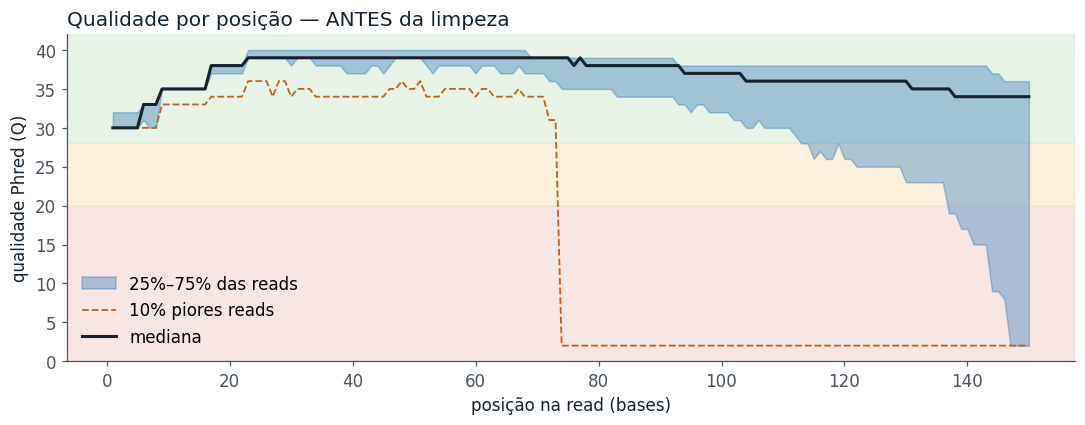

A mediana cai abaixo de Q30 em nenhuma posição.
A mediana cai abaixo de Q20 em nenhuma posição.


In [6]:
def qual_para_array(qual):
    """Linha de qualidade (texto) → vetor numpy de notas Q."""
    return np.frombuffer(qual.encode(), dtype=np.uint8).astype(float) - 33


def matriz_qualidade(lista_reads):
    """Monta a matriz [reads × posições] de notas Q. Posições que não existem ficam 'NaN' (vazio)."""
    largura = max(len(r[2]) for r in lista_reads)
    M = np.full((len(lista_reads), largura), np.nan)
    for i, (_, _, q) in enumerate(lista_reads):
        M[i, :len(q)] = qual_para_array(q)
    return M


def grafico_qualidade(M, ax, titulo):
    """Desenha o 'Per base sequence quality' (versão simplificada)."""
    x = np.arange(1, M.shape[1] + 1)
    mediana = np.nanmedian(M, axis=0)
    q25, q75 = np.nanpercentile(M, [25, 75], axis=0)
    q10 = np.nanpercentile(M, 10, axis=0)
    ax.axhspan(0, 20, color="#F4D6D2", alpha=0.6)      # vermelho: ruim
    ax.axhspan(20, 28, color="#F8E7C6", alpha=0.6)     # amarelo: atenção
    ax.axhspan(28, 42, color="#D8EBD8", alpha=0.6)     # verde: bom
    ax.fill_between(x, q25, q75, color=COR_B, alpha=0.35, label="25%–75% das reads")
    ax.plot(x, q10, color=COR_A, lw=1.2, ls="--", label="10% piores reads")
    ax.plot(x, mediana, color=TINTA, lw=2, label="mediana")
    ax.set_ylim(0, 42)
    ax.set_xlabel("posição na read (bases)")
    ax.set_ylabel("qualidade Phred (Q)")
    ax.set_title(titulo, loc="left", color=TINTA)
    ax.grid(False)


M_antes = matriz_qualidade(reads)

fig, ax = plt.subplots(figsize=(10, 4))
grafico_qualidade(M_antes, ax, "Qualidade por posição — ANTES da limpeza")
ax.legend(frameon=False, loc="lower left")
plt.tight_layout()
plt.show()

mediana_pos = np.nanmedian(M_antes, axis=0)
for limite in (30, 20):
    abaixo = np.where(mediana_pos < limite)[0]
    quando = f"a partir da posição {abaixo[0] + 1}" if len(abaixo) else "em nenhuma posição"
    print(f"A mediana cai abaixo de Q{limite} {quando}.")

**Pergunta A.3** — Em que posição a qualidade começa a cair? Compare com o gráfico do FastQC que você gerou no Galaxy: a forma é parecida? (Lembre: aqui usamos só as primeiras 20 mil reads.)

**Pergunta A.4** — A linha tracejada laranja (10% piores reads) cai muito mais que a mediana. O que isso diz sobre as reads: **todas** pioram igual ou **algumas** são bem piores que as outras?

## A4. Outros módulos do FastQC: qualidade média por read, %GC e adaptadores

- **Qualidade média por read** (*Per sequence quality scores*): um pico em Q30 ou mais é bom; uma "cauda" à esquerda indica um grupo de reads ruins.
- **%GC** (*Per sequence GC content*): proporção de G+C em cada read. Para uma bactéria, esperamos uma curva em forma de **sino** centrada no %GC do genoma (≈ 50% na *E. coli*). Dois picos podem indicar **contaminação** por outro organismo.
- **Conteúdo de adaptador** (*Adapter content*): em que posição aparece o adaptador. Aqui procuramos os 13 primeiros nucleotídeos dele dentro de cada read.

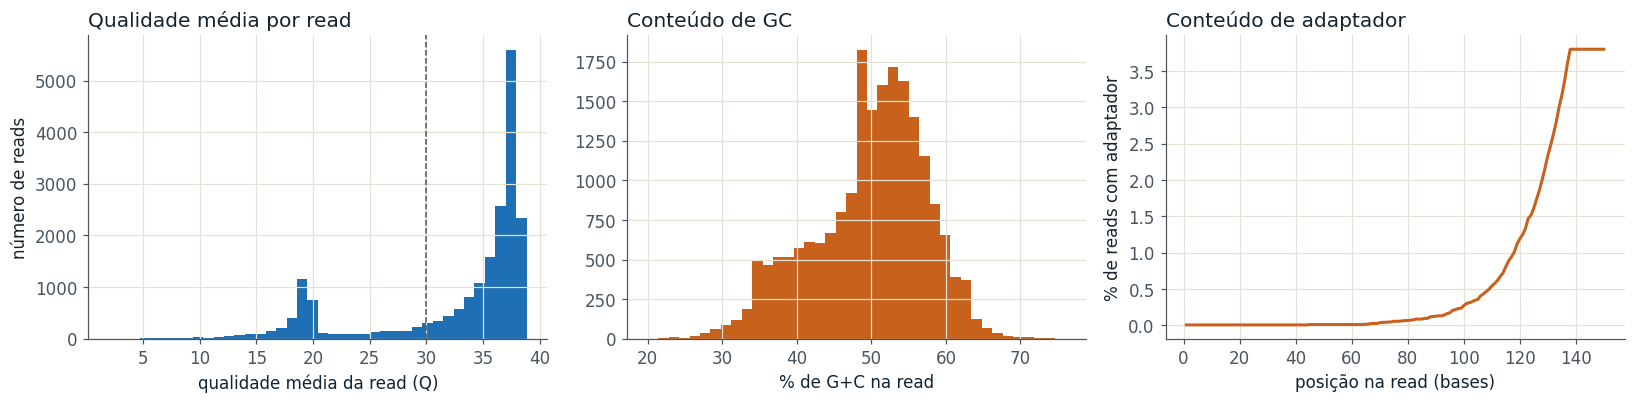

Reads com adaptador: 760 de 20000 (3.8%)
%GC mediano: 51.3%   |   Qualidade média mediana por read: Q36.3


In [7]:
qual_media_read = np.nanmean(M_antes, axis=1)                       # média de Q de cada read
gc = np.array([(s.count("G") + s.count("C")) / len(s) * 100 for _, s, _ in reads])

# .find() devolve a posição onde o texto aparece, ou -1 se não aparece
pos_adaptador = np.array([s.find(ADAPT_CURTO) for _, s, _ in reads])
tem_adaptador = pos_adaptador >= 0

fig, eixos = plt.subplots(1, 3, figsize=(15, 3.8))

eixos[0].hist(qual_media_read, bins=40, color=COR_B)
eixos[0].axvline(30, color=TINTA_SUAVE, ls="--", lw=1)
eixos[0].set_xlabel("qualidade média da read (Q)")
eixos[0].set_ylabel("número de reads")
eixos[0].set_title("Qualidade média por read", loc="left", color=TINTA)

eixos[1].hist(gc, bins=40, color=COR_A)
eixos[1].set_xlabel("% de G+C na read")
eixos[1].set_title("Conteúdo de GC", loc="left", color=TINTA)

largura = M_antes.shape[1]
# % de reads em que o adaptador JÁ apareceu até cada posição (curva acumulada, como o FastQC)
acumulado = [((pos_adaptador >= 0) & (pos_adaptador <= p)).mean() * 100 for p in range(largura)]
eixos[2].plot(range(1, largura + 1), acumulado, color=COR_A, lw=2)
eixos[2].set_xlabel("posição na read (bases)")
eixos[2].set_ylabel("% de reads com adaptador")
eixos[2].set_title("Conteúdo de adaptador", loc="left", color=TINTA)

plt.tight_layout()
plt.show()

print(f"Reads com adaptador: {tem_adaptador.sum()} de {len(reads)} ({tem_adaptador.mean():.1%})")
print(f"%GC mediano: {np.median(gc):.1f}%   |   Qualidade média mediana por read: Q{np.median(qual_media_read):.1f}")

**Pergunta A.5** — Qual a porcentagem de reads com adaptador? Compare com o módulo **Adapter Content** do seu relatório do FastQC no Galaxy.

**Pergunta A.6** — O %GC mediano está perto do esperado para *E. coli* (≈ 50%)? Se o dado fosse simulado, o que você esperaria? *(Dica: o "genoma" simulado é sorteado com A, C, G, T em partes iguais.)*

## A5. Limpeza: nossa versão simplificada do Trimmomatic

No Galaxy você usou três operações do Trimmomatic. Vamos escrever as nossas, em versão didática:

| Operação | O que faz | Nossa função |
|---|---|---|
| **ILLUMINACLIP** | Remove o adaptador (e o que vem depois) | `remover_adaptador` |
| **SLIDINGWINDOW:4:20** | Percorre a read em **janelas de 4 bases**; quando a qualidade **média** da janela fica abaixo de 20, corta dali em diante | `janela_deslizante` |
| **MINLEN:36** | Descarta reads que ficaram curtas demais | filtro por tamanho |

> **Atenção:** estas são versões **simplificadas**. O Trimmomatic real é mais refinado (por exemplo, reconhece adaptadores **parciais** no fim da read, enquanto a nossa busca só acha o trecho completo dos 13 primeiros nucleotídeos). Por isso os números não serão idênticos aos do Galaxy.

In [8]:
def remover_adaptador(seq, qual, adaptador=ADAPT_CURTO):
    """Se achar o adaptador, corta a read ali (o adaptador e tudo depois dele saem)."""
    i = seq.find(adaptador)
    if i >= 0:
        return seq[:i], qual[:i]
    return seq, qual


def janela_deslizante(seq, qual, tamanho=4, q_min=20):
    """Corta a read na primeira janela de 'tamanho' bases cuja qualidade média fica abaixo de q_min."""
    q = qual_para_array(qual)
    if len(q) < tamanho:
        return seq, qual
    # np.convolve com vetor de 1/tamanho = média móvel (média de cada janela)
    medias = np.convolve(q, np.ones(tamanho) / tamanho, mode="valid")
    ruins = np.where(medias < q_min)[0]              # janelas com média abaixo do limite
    corte = ruins[0] if len(ruins) else len(seq)     # corta no início da primeira janela ruim
    return seq[:corte], qual[:corte]


def aparar(lista_reads, tam_janela=4, q_min=20, tam_minimo=36):
    """Aplica as 3 operações e devolve (reads_que_ficaram, contagem_de_cada_destino)."""
    ficaram, contagem = [], collections.Counter()
    for ident, seq, qual in lista_reads:
        original = len(seq)
        seq, qual = remover_adaptador(seq, qual)
        seq, qual = janela_deslizante(seq, qual, tam_janela, q_min)
        if len(seq) < tam_minimo:
            contagem["descartada (curta demais)"] += 1
        else:
            ficaram.append((ident, seq, qual))
            contagem["mantida inteira" if len(seq) == original else "mantida e aparada"] += 1
    return ficaram, contagem


reads_limpas, contagem = aparar(reads)

print(f"Reads de entrada : {len(reads)}")
for destino, n in contagem.items():
    print(f"  {destino:<28}: {n:>6}  ({n / len(reads):.1%})")

comp_antes = np.mean([len(r[1]) for r in reads])
comp_depois = np.mean([len(r[1]) for r in reads_limpas])
print(f"\nComprimento médio: {comp_antes:.1f} → {comp_depois:.1f} bases")
adapt_depois = np.mean([r[1].find(ADAPT_CURTO) >= 0 for r in reads_limpas])
print(f"Reads com adaptador: {tem_adaptador.mean():.1%} → {adapt_depois:.1%}")

Reads de entrada : 20000
  mantida e aparada           :   7923  (39.6%)
  mantida inteira             :  11396  (57.0%)
  descartada (curta demais)   :    681  (3.4%)

Comprimento médio: 150.0 → 129.6 bases
Reads com adaptador: 3.8% → 0.0%


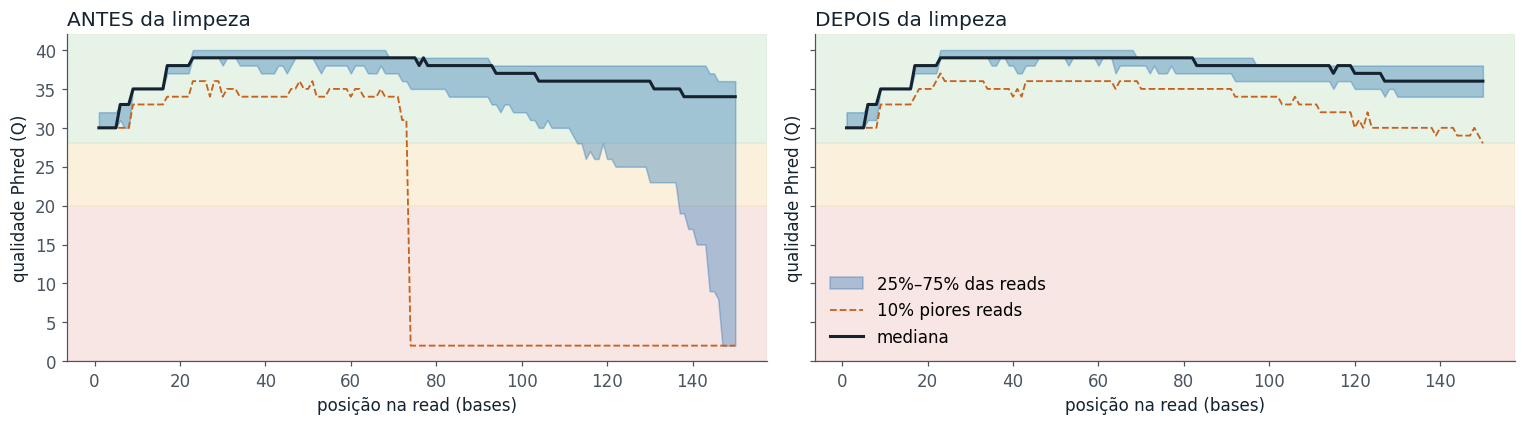

Arquivo salvo: reads_limpas.fastq


In [9]:
# Antes × depois, lado a lado (mesma escala vertical, para a comparação ser honesta)
M_depois = matriz_qualidade(reads_limpas)

fig, eixos = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
grafico_qualidade(M_antes, eixos[0], "ANTES da limpeza")
grafico_qualidade(M_depois, eixos[1], "DEPOIS da limpeza")
eixos[1].legend(frameon=False, loc="lower left")
plt.tight_layout()
plt.show()

# Salva as reads limpas num arquivo FASTQ (as mesmas 4 linhas por read que já conhecemos)
with open("reads_limpas.fastq", "w") as saida:
    for ident, seq, qual in reads_limpas:
        saida.write(f"@{ident}\n{seq}\n+\n{qual}\n")
print("Arquivo salvo: reads_limpas.fastq")

**Pergunta A.7** — A qualidade do final das reads melhorou? Por que o gráfico "depois" fica com **menos posições** à direita (as reads ficaram mais curtas)?

**Pergunta A.8** — Qual a porcentagem de reads descartadas? Compare com o resumo do Trimmomatic no Galaxy (*Input Read Pairs* × *Both Surviving*). Se os números forem diferentes, liste duas razões possíveis (dica: leia o aviso antes do código e lembre que aqui usamos só o R1).

**Pergunta A.9** — Se você aumentasse `q_min` de 20 para 30 (mais rigoroso), esperaria **mais** ou **menos** reads sobrevivendo? E reads mais **longas** ou mais **curtas**? Teste: `aparar(reads, q_min=30)`.

---
# PARTE B — Alinhamento por dentro: do mini-alinhador ao SAM e ao `flagstat`

No Passo 5 o Bowtie2 posicionou milhões de reads num genoma de referência e, no Passo 6, o `samtools flagstat` resumiu o resultado. Agora vamos **construir um alinhador minúsculo** para entender a ideia — e ler o arquivo SAM que ele produz.

## B1. A ideia de um alinhador: sementes (*seeds*)

Comparar cada read com **todas** as posições do genoma seria lento demais. Os alinhadores reais usam um **índice** do genoma (o Bowtie2 e o BWA usam a transformada de Burrows-Wheeler, uma técnica muito eficiente de compressão e busca). A **ideia** que vamos reproduzir é a mesma de um índice de livro:

1. **Indexar:** guardar onde cada trecho de 12 bases ("semente") aparece no genoma.
2. **Buscar:** pegar pequenos trechos da read, procurar no índice e ver **onde** eles aparecem.
3. **Conferir:** nas posições candidatas, contar **quantas bases diferem** (*mismatches*).
4. **Decidir:** se a read cabe com poucas diferenças, ela está **alinhada** ali. Se não, fica **sem alinhar**.

> **Dados didáticos:** usamos um **genoma de brinquedo de 3.000 bases** e reads **simuladas** (pares R1/R2, com 1% de erros e 5% de reads "estranhas", de DNA que não pertence ao genoma, como contaminação). Assim a conta roda em segundos e **sabemos a resposta certa**. O nosso alinhador **não** trata inserções/deleções, só substituições.

In [10]:
# ---------- 1) Um "genoma" de brinquedo ----------
rng = np.random.default_rng(7)                   # semente fixa: todo mundo obtém o mesmo resultado
GENOMA = "".join(rng.choice(list("ACGT"), 3000))
NOME_REF = "refToy"
TAM_READ = 75

# ---------- 2) Simula fragmentos sequenciados nas duas pontas (paired-end) ----------
def com_erros(seq, taxa, r):
    """Troca algumas bases ao acaso (erros de sequenciamento)."""
    seq = list(seq)
    for j in np.where(r.random(len(seq)) < taxa)[0]:
        seq[j] = r.choice([b for b in "ACGT" if b != seq[j]])
    return "".join(seq)


def simular_pares(n=400, erro=0.01, frac_estranha=0.05, semente=3):
    r = np.random.default_rng(semente)
    pares = []
    for i in range(n):
        if r.random() < frac_estranha:                       # DNA que NÃO é do genoma (contaminação)
            r1 = "".join(r.choice(list("ACGT"), TAM_READ))
            r2 = "".join(r.choice(list("ACGT"), TAM_READ))
        else:
            tam_frag = int(np.clip(r.normal(250, 30), 100, 400))          # tamanho do fragmento
            ini = int(r.integers(0, len(GENOMA) - tam_frag + 1))
            frag = GENOMA[ini: ini + tam_frag]
            if r.random() < 0.5:                             # o fragmento pode vir de qualquer fita
                frag = revcomp(frag)
            r1 = com_erros(frag[:TAM_READ], erro, r)         # R1: lê a ponta esquerda do fragmento
            r2 = com_erros(revcomp(frag[-TAM_READ:]), erro, r)   # R2: lê a ponta direita, na fita oposta
        pares.append((f"par{i + 1:03d}", r1, r2))
    return pares


pares = simular_pares()
print("Fragmentos simulados:", len(pares))
print("Exemplo, par001:\n  R1:", pares[0][1], "\n  R2:", pares[0][2])

Fragmentos simulados: 400
Exemplo, par001:
  R1: GACTTGTCAAATTAGAGAGAGTGCTCTTCGTAACATTCCGCAGGATGTTGCCGAAGTTTACCGGAGGTGATAATC 
  R2: GGGGTTTGGTTAATAAGTAAAGACCTTTTACTGTGAGAACGTTAAATTAGGAGATGACTCAGTCGAGTGGGGTGT


In [11]:
# ---------- 3) Indexar o genoma: onde cada "semente" de 12 bases aparece ----------
K = 12
indice = collections.defaultdict(list)             # dicionário: semente → lista de posições
for i in range(len(GENOMA) - K + 1):
    indice[GENOMA[i: i + K]].append(i)
print(f"Índice pronto: {len(indice)} sementes distintas de {K} bases.")


# ---------- 4) Alinhar uma read ----------
def alinhar_read(seq, max_mism=6):
    """Procura a posição da read no genoma, nas duas fitas.

    Devolve (posição_inicial_0based, fita, mismatches, posição_única?) ou None se não alinhou.
    """
    candidatos_ok = []
    for fita, s in (("+", seq), ("-", revcomp(seq))):         # testa a read e o seu reverso-complementar
        posicoes = set()
        for deslocamento in range(0, len(s) - K + 1, 8):      # uma semente a cada 8 bases
            for p in indice.get(s[deslocamento: deslocamento + K], []):
                posicoes.add(p - deslocamento)                # onde a read INTEIRA começaria
        for ini in posicoes:
            if ini < 0 or ini + len(s) > len(GENOMA):
                continue
            # compara base a base com o genoma e conta as diferenças
            mism = sum(a != b for a, b in zip(s, GENOMA[ini: ini + len(s)]))
            if mism <= max_mism:
                candidatos_ok.append((mism, ini, fita))
    if not candidatos_ok:
        return None                                           # não coube em lugar nenhum
    candidatos_ok.sort()                                      # o melhor (menos diferenças) primeiro
    mism, ini, fita = candidatos_ok[0]
    unica = len(candidatos_ok) == 1 or candidatos_ok[1][0] > mism
    return ini, fita, mism, unica


teste = alinhar_read(pares[0][1])
print("\nAlinhamento da R1 do par001 → (posição, fita, mismatches, única):", teste)

Índice pronto: 2988 sementes distintas de 12 bases.

Alinhamento da R1 do par001 → (posição, fita, mismatches, única): (512, '+', 1, True)


## B2. Escrevendo o resultado no formato SAM

Cada read vira **uma linha** com 11 colunas obrigatórias (as mesmas que estudamos no material de apoio). Para escrever o **FLAG** corretamente, somamos as "bandeiras":

| Valor | Significado | | Valor | Significado |
|---|---|---|---|---|
| 1 | read pareada | | 16 | read na fita reversa |
| 2 | par alinhado corretamente | | 32 | parceira na fita reversa |
| 4 | read **não** alinhou | | 64 | primeira do par (R1) |
| 8 | parceira **não** alinhou | | 128 | segunda do par (R2) |

Regras que nosso código segue: se **as duas** alinham em **fitas opostas**, com a "direta" à esquerda e distância razoável entre elas → **par correto** (bandeira 2). Se só uma alinha, a outra herda a posição dela (convenção do SAM). Se nenhuma alinha → linhas "sem alinhar" (`*`).

In [12]:
def linhas_sam_do_par(nome, r1, r2):
    """Alinha as duas reads do par e devolve as duas linhas SAM correspondentes."""
    leituras = [r1, r2]
    alin = [alinhar_read(r1), alinhar_read(r2)]
    linhas = []
    for idx in (0, 1):                       # idx 0 = R1, idx 1 = R2
        outro = 1 - idx
        a, b = alin[idx], alin[outro]
        flag = 1 | (64 if idx == 0 else 128)                 # pareada + (primeira ou segunda)

        if a is None:                                        # ESTA read não alinhou
            flag |= 4
            if b is None:                                    # nenhuma das duas alinhou
                flag |= 8
                campos = [nome, flag, "*", 0, 0, "*", "*", 0, 0, leituras[idx], "*"]
            else:                                            # a parceira alinhou: herda a posição dela
                if b[1] == "-":
                    flag |= 32
                campos = [nome, flag, NOME_REF, b[0] + 1, 0, "*", "=", b[0] + 1, 0, leituras[idx], "*"]
        else:                                                # ESTA read alinhou
            ini, fita, mism, unica = a
            seq_sam = leituras[idx] if fita == "+" else revcomp(leituras[idx])   # SAM guarda a fita da referência
            if fita == "-":
                flag |= 16
            mapq = 42 if (unica and mism <= 3) else (20 if unica else 1)
            if b is None:                                    # a parceira NÃO alinhou
                flag |= 8
                rnext, pnext, tlen = "=", ini + 1, 0
            else:
                ini_b, fita_b = b[0], b[1]
                if fita_b == "-":
                    flag |= 32
                esq = min(ini, ini_b)
                dir_ = max(ini + len(seq_sam), ini_b + TAM_READ)
                tlen = dir_ - esq                            # tamanho do fragmento
                ini_fwd = ini if fita == "+" else ini_b
                ini_rev = ini_b if fita == "+" else ini
                if fita != fita_b and ini_fwd <= ini_rev and 50 <= tlen <= 600:
                    flag |= 2                                # par "correto"
                sinal = 1 if (ini < ini_b or (ini == ini_b and idx == 0)) else -1
                rnext, pnext, tlen = "=", ini_b + 1, sinal * tlen
            campos = [nome, flag, NOME_REF, ini + 1, mapq, f"{len(seq_sam)}M", rnext, pnext, tlen, seq_sam, "*",
                      f"NM:i:{mism}"]                        # NM = nº de diferenças em relação à referência
        linhas.append("\t".join(map(str, campos)))
    return linhas


sam_linhas = ["@HD\tVN:1.6\tSO:unsorted", f"@SQ\tSN:{NOME_REF}\tLN:{len(GENOMA)}"]   # cabeçalho
for nome, r1, r2 in pares:
    sam_linhas += linhas_sam_do_par(nome, r1, r2)

with open("alinhamento_toy.sam", "w") as saida:
    saida.write("\n".join(sam_linhas) + "\n")

print("Primeiras linhas do arquivo SAM (os campos são separados por TAB):\n")
for linha in sam_linhas[:7]:
    print(linha[:150] + ("…" if len(linha) > 150 else ""))

Primeiras linhas do arquivo SAM (os campos são separados por TAB):

@HD	VN:1.6	SO:unsorted
@SQ	SN:refToy	LN:3000
par001	99	refToy	513	42	75M	=	611	173	GACTTGTCAAATTAGAGAGAGTGCTCTTCGTAACATTCCGCAGGATGTTGCCGAAGTTTACCGGAGGTGATAATC	*	NM:i:1
par001	147	refToy	611	42	75M	=	513	-173	ACACCCCACTCGACTGAGTCATCTCCTAATTTAACGTTCTCACAGTAAAAGGTCTTTACTTATTAACCAAACCCC	*	NM:i:0
par002	83	refToy	2725	42	75M	=	2546	-254	CGCTCCTTGACGCCCCCTCGTATCATATAGATGTTGTGAAGCTGATACCCTAAGCCTTAACGCGACAAACGGTAG	*	NM:i:2
par002	163	refToy	2546	42	75M	=	2725	254	GGCGGCCGCTCACTCCATACCGCTTCTACTGATTCAGGCGGTTTAATTGCTAGCTGCTGCCCGCGGAGATTATCG	*	NM:i:0
par003	83	refToy	1653	42	75M	=	1513	-215	GAGAGCCCGTGCCCCGTACATGATCCCGGAGCTGTCGCTGTGTAAGAAGTCAGCTAATGCCGATCTAATGTGCGC	*	NM:i:1


## B3. Lendo um SAM: colunas, FLAG e CIGAR

Escrever um parser (leitor) de SAM é mais simples do que parece: ignorar as linhas de cabeçalho (começam com `@`) e separar o resto em colunas. Depois criamos duas funções tradutoras:

- **`decodificar_flag`**: transforma o número do FLAG na lista de propriedades;
- **`ler_cigar`**: transforma `8M2I4M1D3M` em pares *(8, M), (2, I)...* e calcula quantas bases da read e da referência o alinhamento "consome".

Como teste, usamos o **exemplo clássico do artigo que definiu o formato SAM**, o mesmo que aparece nos slides: uma referência de 45 bases e 6 alinhamentos.

In [13]:
COLUNAS_SAM = ["QNAME", "FLAG", "RNAME", "POS", "MAPQ", "CIGAR", "RNEXT", "PNEXT", "TLEN", "SEQ", "QUAL"]

def ler_sam(linhas):
    """Transforma linhas de texto SAM numa tabela (pandas). Ignora o cabeçalho (@...)."""
    registros = []
    for linha in linhas:
        if linha.startswith("@") or not linha.strip():
            continue
        campos = linha.split()                         # separa por espaço ou TAB
        registro = dict(zip(COLUNAS_SAM, campos[:11]))
        registro["TAGS"] = " ".join(campos[11:])       # campos opcionais (ex.: NM:i:1)
        registros.append(registro)
    tabela = pd.DataFrame(registros)
    for coluna in ("FLAG", "POS", "MAPQ", "PNEXT", "TLEN"):
        tabela[coluna] = tabela[coluna].astype(int)
    return tabela


BANDEIRAS = {1: "pareada", 2: "par correto", 4: "read sem alinhar", 8: "parceira sem alinhar",
             16: "read na fita reversa", 32: "parceira na fita reversa",
             64: "primeira do par (R1)", 128: "segunda do par (R2)",
             256: "alinhamento secundário", 512: "reprovou no QC", 1024: "duplicata de PCR",
             2048: "alinhamento suplementar"}

def decodificar_flag(flag):
    """Lista as propriedades 'ligadas' no número FLAG. O operador & testa um bit por vez."""
    return [nome for bit, nome in BANDEIRAS.items() if flag & bit]


def ler_cigar(cigar):
    """'8M2I4M1D3M' → [(8,'M'), (2,'I'), (4,'M'), (1,'D'), (3,'M')]"""
    if cigar == "*":
        return []
    return [(int(n), op) for n, op in re.findall(r"(\d+)([MIDNSHP=X])", cigar)]


def comprimentos_cigar(cigar):
    """Quantas bases o CIGAR consome da READ e da REFERÊNCIA.

    M, =, X consomem as duas · I e S consomem só a read · D e N consomem só a referência
    H e P não consomem nenhuma.
    """
    ops = ler_cigar(cigar)
    na_read = sum(n for n, op in ops if op in "MIS=X")
    na_ref = sum(n for n, op in ops if op in "MDN=X")
    return na_read, na_ref


NOMES_OP = {"M": "alinhadas", "I": "inseridas (só na read)", "D": "deletadas (só na referência)",
            "N": "região pulada (íntron)", "S": "ignoradas nas pontas (soft clip)",
            "H": "removidas das pontas (hard clip)", "P": "preenchimento (padding)"}

def narrar_cigar(cigar):
    """Descreve o CIGAR em português."""
    return " → ".join(f"{n} base(s) {NOMES_OP[op]}" for n, op in ler_cigar(cigar))


print(narrar_cigar("8M2I4M1D3M"))

8 base(s) alinhadas → 2 base(s) inseridas (só na read) → 4 base(s) alinhadas → 1 base(s) deletadas (só na referência) → 3 base(s) alinhadas


In [14]:
# O exemplo clássico do artigo do formato SAM (o mesmo dos slides)
EXEMPLO_LIVRO = """
@SQ SN:ref LN:45
r001 163 ref  7 30 8M2I4M1D3M = 37  39 TTAGATAAAGGATACTA *
r002   0 ref  9 30 3S6M1P1I4M * 0   0 AAAAGATAAGGATA *
r003   0 ref  9 30 5H6M       * 0   0 AGCTAA * NM:i:1
r004   0 ref 16 30 6M14N5M    * 0   0 ATAGCTTCAGC *
r003  16 ref 29 30 6H5M       * 0   0 TAGGC * NM:i:0
r001  83 ref 37 30 9M         = 7 -39 CAGCGCCAT *
""".strip().splitlines()

livro = ler_sam(EXEMPLO_LIVRO)

# Para cada linha: decodifica o FLAG e confere se o CIGAR "fecha" com o tamanho da sequência
livro["propriedades (FLAG)"] = livro["FLAG"].apply(lambda f: ", ".join(decodificar_flag(f)) or "—")
livro["bases da read pelo CIGAR"] = livro["CIGAR"].apply(lambda c: comprimentos_cigar(c)[0])
livro["tamanho de SEQ"] = livro["SEQ"].str.len()
livro["CIGAR confere?"] = livro["bases da read pelo CIGAR"] == livro["tamanho de SEQ"]
livro["começa na ref"] = livro["POS"]
livro["termina na ref"] = livro["POS"] + livro["CIGAR"].apply(lambda c: comprimentos_cigar(c)[1]) - 1

livro[["QNAME", "FLAG", "propriedades (FLAG)", "CIGAR", "bases da read pelo CIGAR", "tamanho de SEQ",
       "CIGAR confere?", "começa na ref", "termina na ref"]]

,QNAME,FLAG,propriedades (FLAG),CIGAR,bases da read pelo CIGAR,tamanho de SEQ,CIGAR confere?,começa na ref,termina na ref
0,r001,163,"pareada, par correto, parceira na fita reversa...",8M2I4M1D3M,17,17,True,7,22
1,r002,0,—,3S6M1P1I4M,14,14,True,9,18
2,r003,0,—,5H6M,6,6,True,9,14
3,r004,0,—,6M14N5M,11,11,True,16,40
4,r003,16,read na fita reversa,6H5M,5,5,True,29,33
5,r001,83,"pareada, par correto, read na fita reversa, pr...",9M,9,9,True,37,45


**Pergunta B.1** — Para a linha `r001` com FLAG **163**, confira a conta: 163 = 128 + 32 + 2 + 1. O que cada parcela significa? (A tabela acima já traduziu; você concorda?)

**Pergunta B.2** — Em `r004` o CIGAR é `6M14N5M`. O `N` consome **14 posições da referência** mas **nenhuma da read**. Em que tipo de experimento isso aparece? *(Dica: pense em RNA-seq e íntrons; revisitaremos isso na Unidade 4.)*

**Pergunta B.3** — Por que a coluna **"CIGAR confere?"** é um bom teste de sanidade para qualquer arquivo SAM?

Agora a mesma leitura aplicada ao **nosso alinhamento de brinquedo**:

In [15]:
sam = ler_sam(sam_linhas)
print(f"{len(sam)} linhas de alinhamento (2 por par).")

# Quais combinações de FLAG apareceram, e o que significam?
contagem_flags = sam["FLAG"].value_counts().rename_axis("FLAG").reset_index(name="nº de reads")
contagem_flags["propriedades"] = contagem_flags["FLAG"].apply(lambda f: ", ".join(decodificar_flag(f)))
contagem_flags

800 linhas de alinhamento (2 por par).


,FLAG,nº de reads,propriedades
0,163,195,"pareada, par correto, parceira na fita reversa..."
1,83,195,"pareada, par correto, read na fita reversa, pr..."
2,147,183,"pareada, par correto, read na fita reversa, se..."
3,99,183,"pareada, par correto, parceira na fita reversa..."
4,77,22,"pareada, read sem alinhar, parceira sem alinha..."
5,141,22,"pareada, read sem alinhar, parceira sem alinha..."


## B4. Reproduzindo o `samtools flagstat`

O `flagstat` não faz mágica: ele **lê o FLAG de cada read** e **conta**. Vamos escrever o nosso, com a mesma saída. O operador `&` ("E bit a bit") testa se uma bandeira está ligada: por exemplo `flag & 4` é diferente de zero quando a read **não alinhou**.

In [16]:
def flagstat(tabela):
    """Reproduz (de forma simplificada) a saída do 'samtools flagstat' a partir de uma tabela SAM."""
    f = tabela["FLAG"].astype(int)

    def conta(mascara):
        """Devolve 'aprovadas no QC + reprovadas no QC' (bit 512 = reprovou no controle de qualidade)."""
        reprovou = (f & 512) != 0
        return int((mascara & ~reprovou).sum()), int((mascara & reprovou).sum())

    todas        = f >= 0                                  # todas as linhas
    secundarias  = (f & 256) != 0
    suplement    = (f & 2048) != 0
    duplicatas   = (f & 1024) != 0
    primarias    = todas & ~secundarias & ~suplement
    alinhadas    = (f & 4) == 0
    pareadas     = (f & 1) != 0
    read1        = pareadas & ((f & 64) != 0)
    read2        = pareadas & ((f & 128) != 0)
    par_correto  = pareadas & ((f & 2) != 0) & alinhadas
    ambas        = pareadas & alinhadas & ((f & 8) == 0)   # ela e a parceira alinharam
    singletons   = pareadas & alinhadas & ((f & 8) != 0)   # ela alinhou, a parceira não
    outro_cromo  = (pareadas & alinhadas & ((f & 8) == 0)
                    & (tabela["RNEXT"] != "=") & (tabela["RNEXT"] != "*") & (tabela["RNAME"] != tabela["RNEXT"]))

    total = int(len(f))
    prim = conta(primarias)[0] + conta(primarias)[1]
    pct = lambda n: f"{100 * n / total:.2f}%" if total else "N/A"
    n_al, n_par, n_sing = conta(alinhadas)[0], conta(par_correto)[0], conta(singletons)[0]

    linhas = [
        "{} + {} in total (QC-passed reads + QC-failed reads)".format(*conta(todas)),
        "{} + {} primary".format(*conta(primarias)),
        "{} + {} secondary".format(*conta(secundarias)),
        "{} + {} supplementary".format(*conta(suplement)),
        "{} + {} duplicates".format(*conta(duplicatas)),
        f"{n_al} + {conta(alinhadas)[1]} mapped ({pct(n_al)} : N/A)",
        "{} + {} paired in sequencing".format(*conta(pareadas)),
        "{} + {} read1".format(*conta(read1)),
        "{} + {} read2".format(*conta(read2)),
        f"{n_par} + {conta(par_correto)[1]} properly paired ({pct(n_par)} : N/A)",
        "{} + {} with itself and mate mapped".format(*conta(ambas)),
        f"{n_sing} + {conta(singletons)[1]} singletons ({pct(n_sing)} : N/A)",
        "{} + {} with mate mapped to a different chr".format(*conta(outro_cromo)),
    ]
    return "\n".join(linhas)


print(flagstat(sam))

800 + 0 in total (QC-passed reads + QC-failed reads)
800 + 0 primary
0 + 0 secondary
0 + 0 supplementary
0 + 0 duplicates
756 + 0 mapped (94.50% : N/A)
800 + 0 paired in sequencing
400 + 0 read1
400 + 0 read2
756 + 0 properly paired (94.50% : N/A)
756 + 0 with itself and mate mapped
0 + 0 singletons (0.00% : N/A)
0 + 0 with mate mapped to a different chr


**Pergunta B.4** — Compare com a saída do `flagstat` do Galaxy (próxima seção). A **estrutura** é a mesma? O que mudou nos **números** e por quê? *(Dica: aqui sabemos que 5% dos fragmentos são "contaminação" que **não** pertence ao genoma.)*

**Pergunta B.5** — Qual o percentual de reads **alinhadas** do nosso brinquedo? E o de **pares corretos**? Por que o segundo é menor ou igual ao primeiro?

## B5. Interpretando o SEU `flagstat` do Galaxy

Cole abaixo o resultado do **Samtools flagstat** que você obteve no Passo 6 da prática (o texto de exemplo já vem preenchido com o resultado obtido numa execução de referência da aula, **substitua pelo seu**). O código converte o texto numa tabela, recalcula os percentuais e faz alguns **testes de sanidade**.

In [17]:
# >>>>>>> COLE AQUI o resultado do seu "Samtools flagstat" (substitua o texto entre as aspas triplas) <<<<<<<
FLAGSTAT_GALAXY = """
2895102 + 0 in total (QC-passed reads + QC-failed reads)
2895102 + 0 primary
0 + 0 secondary
0 + 0 supplementary
0 + 0 duplicates
0 + 0 primary duplicates
2765970 + 0 mapped (95.54% : N/A)
2765970 + 0 primary mapped (95.54% : N/A)
2895102 + 0 paired in sequencing
1447551 + 0 read1
1447551 + 0 read2
2632294 + 0 properly paired (90.92% : N/A)
2755020 + 0 with itself and mate mapped
10950 + 0 singletons (0.38% : N/A)
0 + 0 with mate mapped to a different chr
0 + 0 with mate mapped to a different chr (mapQ>=5)
"""

def ler_flagstat(texto):
    """Transforma o texto do flagstat num dicionário {descrição: número de reads (aprovadas no QC)}."""
    dados = {}
    for linha in texto.strip().splitlines():
        achado = re.match(r"(\d+) \+ (\d+) (.*?)(?: \(.*\))?$", linha.strip())
        if achado:
            dados[achado.group(3)] = int(achado.group(1))
    return dados


fs = ler_flagstat(FLAGSTAT_GALAXY)
total = fs["in total"]
resumo = pd.DataFrame([
    ("Reads no total", fs["in total"]),
    ("Alinhadas (mapped)", fs["mapped"]),
    ("NÃO alinhadas", total - fs["mapped"]),
    ("Em par correto (properly paired)", fs["properly paired"]),
    ("Singletons (ela alinhou, a parceira não)", fs["singletons"]),
], columns=["categoria", "nº de reads"])
resumo["% do total"] = (100 * resumo["nº de reads"] / total).round(2)
display(resumo)

# ---- Testes de sanidade (o que um bioinformata confere antes de confiar num resultado) ----
print("\nTestes de sanidade:")
print("✔" if fs["read1"] == fs["read2"] else "⚠", "R1 e R2 têm o MESMO número de reads (pareamento íntegro)")
print("✔" if fs["properly paired"] <= fs["mapped"] else "⚠", "pares corretos ≤ reads alinhadas")
print("✔" if fs["with mate mapped to a different chr"] == 0 else "⚠", "nenhuma parceira em outra sequência (esperado: só há 1 cromossomo na referência)")
pct_alinhadas = 100 * fs["mapped"] / total
print("✔" if pct_alinhadas >= 90 else "⚠", f"taxa de alinhamento {pct_alinhadas:.2f}% (acima de 90% sugere amostra e referência compatíveis)")
pct_sing = 100 * fs["singletons"] / total
print("✔" if pct_sing < 2 else "⚠", f"singletons {pct_sing:.2f}% (valores baixos indicam pares bem alinhados)")

,categoria,nº de reads,% do total
0,Reads no total,2895102,100.00
1,Alinhadas (mapped),2765970,95.54
2,NÃO alinhadas,129132,4.46
3,Em par correto (properly paired),2632294,90.92
4,"Singletons (ela alinhou, a parceira não)",10950,0.38



Testes de sanidade:
✔ R1 e R2 têm o MESMO número de reads (pareamento íntegro)
✔ pares corretos ≤ reads alinhadas
✔ nenhuma parceira em outra sequência (esperado: só há 1 cromossomo na referência)
✔ taxa de alinhamento 95.54% (acima de 90% sugere amostra e referência compatíveis)
✔ singletons 0.38% (valores baixos indicam pares bem alinhados)


**Pergunta B.6** — A taxa de alinhamento ficou em ~95%. Cite **duas** explicações biológicas para os ~5% restantes. *(Dica: a referência Sakai é um **parente próximo** da cepa do surto, não a cepa exata, e o arquivo da referência só inclui o cromossomo, não os plasmídeos.)*

**Pergunta B.7** — Se a taxa fosse de **20%**, qual seria a sua primeira suspeita? E se `read1` e `read2` fossem muito diferentes entre si?

**Pergunta B.8** — A linha `duplicates` mostra **0**. Isso significa que **não há** duplicatas de PCR na amostra? *(Resposta: não. Lembre que não rodamos a etapa de marcação de duplicatas; o zero apenas indica que ninguém as marcou.)*

---
# PARTE C — Comparando sequências: alinhamento, E-value, BLAST e conservação

Na Parte B alinhamos **milhões de reads curtas** contra **um** genoma. Agora a pergunta é outra: dada **uma** proteína, **quão parecida** ela é com outra? E **entre milhares** de proteínas conhecidas, quais são as parentes mais próximas? É o que o **BLAST** e o **Clustal Omega** respondem.

## C1. Duas proteínas, um alinhamento

Usaremos duas proteínas humanas que **descendem de um ancestral comum**, mas divergiram ao longo da evolução: as subunidades **alfa** (UniProt **P69905**) e **beta** (UniProt **P68871**) da **hemoglobina**. Vamos baixar as sequências do UniProt. Se o servidor não responder, o caderno usa uma cópia local.

O alinhamento usa:

- uma **matriz de substituição** (**BLOSUM62**): dá nota **positiva** a trocas entre aminoácidos parecidos (ex.: leucina ↔ isoleucina) e nota **negativa** a trocas drásticas;
- uma **penalidade para lacunas** (*gaps*): abrir uma lacuna custa caro (−10) e estendê-la custa pouco (−0,5).

In [18]:
def baixar_fasta_uniprot(acesso, plano_b):
    """Baixa a sequência de uma proteína do UniProt. Se falhar, usa o 'plano_b' (cópia local)."""
    try:
        texto = requests.get(f"https://rest.uniprot.org/uniprotkb/{acesso}.fasta", timeout=30).text
        return "".join(texto.splitlines()[1:]), "UniProt"
    except Exception:
        return plano_b, "cópia local"

HBA_LOCAL = "MVLSPADKTNVKAAWGKVGAHAGEYGAEALERMFLSFPTTKTYFPHFDLSHGSAQVKGHGKKVADALTNAVAHVDDMPNALSALSDLHAHKLRVDPVNFKLLSHCLLVTLAAHLPAEFTPAVHASLDKFLASVSTVLTSKYR"
HBB_LOCAL = "MVHLTPEEKSAVTALWGKVNVDEVGGEALGRLLVVYPWTQRFFESFGDLSTPDAVMGNPKVKAHGKKVLGAFSDGLAHLDNLKGTFATLSELHCDKLHVDPENFRLLGNVLVCVLAHHFGKEFTPPVQAAYQKVVAGVANALAHKYH"

hba, fonte_a = baixar_fasta_uniprot("P69905", HBA_LOCAL)
hbb, fonte_b = baixar_fasta_uniprot("P68871", HBB_LOCAL)
print(f"Hemoglobina alfa (P69905): {len(hba)} aminoácidos  [fonte: {fonte_a}]")
print(f"Hemoglobina beta (P68871): {len(hbb)} aminoácidos  [fonte: {fonte_b}]")

Hemoglobina alfa (P69905): 142 aminoácidos  [fonte: UniProt]
Hemoglobina beta (P68871): 147 aminoácidos  [fonte: UniProt]


In [19]:
# ------ Alinhador "local" (Smith-Waterman): acha o MELHOR TRECHO parecido, como o BLAST ------
alinhador = Align.PairwiseAligner()
alinhador.mode = "local"
alinhador.substitution_matrix = substitution_matrices.load("BLOSUM62")
alinhador.open_gap_score = -10        # custo de ABRIR uma lacuna
alinhador.extend_gap_score = -0.5     # custo de cada base a mais dentro da lacuna

melhor = alinhador.align(hba, hbb)[0]
print("Pontuação do melhor alinhamento local:", melhor.score)
print(melhor)


def identidade(aln, s1, s2):
    """Conta posições idênticas e o comprimento total do alinhamento (a definição usada pelo BLAST)."""
    ident = comp = 0
    c = aln.coordinates                           # trechos alinhados: (início, fim) em cada sequência
    for k in range(c.shape[1] - 1):
        a0, a1, b0, b1 = c[0, k], c[0, k + 1], c[1, k], c[1, k + 1]
        if a1 - a0 == b1 - b0 and a1 > a0:        # trecho alinhado, sem lacuna
            comp += a1 - a0
            ident += sum(x == y for x, y in zip(s1[a0:a1], s2[b0:b1]))
        else:                                     # lacuna
            comp += max(a1 - a0, b1 - b0)
    return ident, comp


ident, comp = identidade(melhor, hba, hbb)
print(f"\nIdentidade: {ident}/{comp} = {ident / comp:.1%}")

Pontuação do melhor alinhamento local: 293.5
target            2 LSPADKTNVKAAWGKVGAHAGEYGAEALERMFLSFPTTKTYFPHF-DLS-----HGSAQV
                  0 |.|..|..|.|.||||--...|.|.|||.|.....|.|...|..|-|||-----.|...|
query             3 LTPEEKSAVTALWGKV--NVDEVGGEALGRLLVVYPWTQRFFESFGDLSTPDAVMGNPKV

target           56 KGHGKKVADALTNAVAHVDDMPNALSALSDLHAHKLRVDPVNFKLLSHCLLVTLAAHLPA
                 60 |.|||||..|.....||.|........||.||..||.|||.||.||...|...||.|...
query            61 KAHGKKVLGAFSDGLAHLDNLKGTFATLSELHCDKLHVDPENFRLLGNVLVCVLAHHFGK

target          116 EFTPAVHASLDKFLASVSTVLTSKY 141
                120 ||||.|.|...|..|.|...|..|| 145
query           121 EFTPPVQAAYQKVVAGVANALAHKY 146


Identidade: 63/145 = 43.4%


**Pergunta C.1** — Qual a identidade entre as duas hemoglobinas? Isso é muito ou pouco para duas proteínas que fazem **um trabalho parecido** (transportar oxigênio)? *(Dica: a identidade fica em torno de 40–45%, bem acima do que o acaso daria, como veremos a seguir.)*

## C2. De onde vem o E-value? Um experimento com embaralhamento

O **E-value** do BLAST responde: *"quantos alinhamentos com pontuação ao menos tão boa quanto essa eu esperaria encontrar **por puro acaso**?"* O BLAST usa uma fórmula estatística (de Karlin e Altschul). Podemos **enxergar a ideia** sem fórmula:

1. **Embaralhe** uma das proteínas (mesmas letras, ordem aleatória: perde-se a biologia, mantém-se a composição).
2. Alinhe a original com a embaralhada e anote a pontuação.
3. Repita **500 vezes**. Isso mostra **como são as pontuações "por acaso"**.
4. Compare com a pontuação do alinhamento **real**.

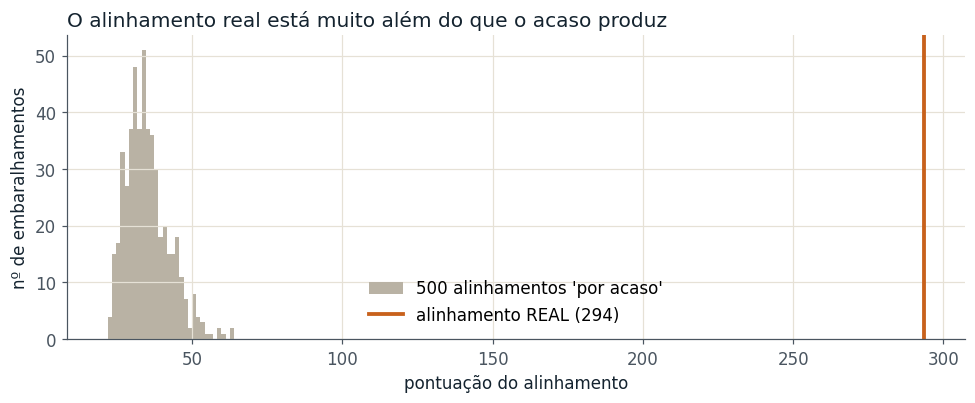

Pontuação 'por acaso': média 35.1, máxima 64.0
Pontuação real        : 293.5
Nenhum dos 500 embaralhamentos chegou perto → p empírico < 0.0020


In [20]:
rng = np.random.default_rng(11)
N_EMBARALHAMENTOS = 500

pontuacoes_acaso = []
letras = list(hbb)
for _ in range(N_EMBARALHAMENTOS):
    rng.shuffle(letras)                                   # embaralha as letras da hemoglobina beta
    pontuacoes_acaso.append(alinhador.score(hba, "".join(letras)))   # .score é mais rápido que .align
pontuacoes_acaso = np.array(pontuacoes_acaso)

# p empírico: fração dos embaralhamentos com pontuação >= à real (+1 evita dar "zero" exato)
p_empirico = (np.sum(pontuacoes_acaso >= melhor.score) + 1) / (N_EMBARALHAMENTOS + 1)

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.hist(pontuacoes_acaso, bins=30, color=COR_NS, label=f"{N_EMBARALHAMENTOS} alinhamentos 'por acaso'")
ax.axvline(melhor.score, color=COR_A, lw=2.5, label=f"alinhamento REAL ({melhor.score:.0f})")
ax.set_xlabel("pontuação do alinhamento")
ax.set_ylabel("nº de embaralhamentos")
ax.set_title("O alinhamento real está muito além do que o acaso produz", loc="left", color=TINTA)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

print(f"Pontuação 'por acaso': média {pontuacoes_acaso.mean():.1f}, máxima {pontuacoes_acaso.max():.1f}")
print(f"Pontuação real        : {melhor.score:.1f}")
print(f"Nenhum dos {N_EMBARALHAMENTOS} embaralhamentos chegou perto → p empírico < {p_empirico:.4f}"
      if p_empirico <= 1 / N_EMBARALHAMENTOS * 1.01 else f"p empírico ≈ {p_empirico:.4f}")

**Pergunta C.2** — O alinhamento real ficou **dentro** ou **muito fora** da distribuição "por acaso"? O que isso diz sobre as duas proteínas serem **homólogas** (terem ancestral comum)?

**Pergunta C.3** — Por que o E-value do BLAST **depende do tamanho do banco**? *(Dica: pense em jogar uma moeda: em 10 jogadas, 8 caras seriam surpreendentes; em 10 milhões de jogadas, "8 caras seguidas" apareceria várias vezes só por sorte. Buscar numa lista enorme faz aparecer acertos "bons" sem significado.)*

## C3. O BLAST pela API (opcional, 1 a 3 minutos)

No Passo 7 você usou o site do BLAST. O Biopython **conversa com o mesmo servidor do NCBI** por programa (`NCBIWWW.qblast`). Vamos rodar um **`blastp`** com a hemoglobina alfa contra o banco **Swiss-Prot** (proteínas revisadas por especialistas; é bem menor que o `nr` do site, por isso a resposta é mais rápida).

> **Boa conduta:** o BLAST do NCBI é um serviço público e **gratuito**. Rode **uma vez** e não repita em *loop*. Se o servidor estiver ocupado, o caderno avisa e você pode usar o site. Para desligar esta célula, mude `RODAR_BLAST` para `False`.

Para cada resultado calculamos o que você viu na tabela do site: **identidade**, **cobertura da consulta** (*query cover*) e **E-value**. **Ignore o primeiro resultado: é a própria sequência.**

In [ ]:
from Bio.Blast import NCBIWWW, NCBIXML

RODAR_BLAST = True                       # mude para False para pular esta etapa
MINHA_SEQUENCIA = hba                    # ← TROQUE pela sequência de proteína da SUA pesquisa (só as letras)

blast_df = None
if RODAR_BLAST:
    try:
        print("Enviando ao NCBI... (pode levar de 30 segundos a alguns minutos)")
        resposta = NCBIWWW.qblast("blastp", "swissprot", MINHA_SEQUENCIA, hitlist_size=15)
        registro = NCBIXML.read(resposta)               # lê o resultado (formato XML)
        linhas = []
        for aln in registro.alignments:
            hsp = aln.hsps[0]                           # o melhor trecho alinhado desta proteína
            linhas.append({
                "proteína": aln.title.split(" ", 1)[1][:60],
                "identidade (%)": round(100 * hsp.identities / hsp.align_length, 1),
                "cobertura da consulta (%)": round(100 * (hsp.query_end - hsp.query_start + 1) / len(MINHA_SEQUENCIA), 1),
                "E-value": hsp.expect,
                "bit score": round(hsp.bits, 1),
            })
        blast_df = pd.DataFrame(linhas)
        display(blast_df)
    except Exception as erro:
        print("Não consegui rodar o BLAST agora:", erro)
        print("Alternativa: use o site https://blast.ncbi.nlm.nih.gov (Protein BLAST) como no Passo 7.")
else:
    print("Etapa do BLAST desligada (RODAR_BLAST = False).")

Enviando ao NCBI... (pode levar de 30 segundos a alguns minutos)


/usr/local/lib/python3.13/dist-packages/Bio/Blast/NCBIWWW.py:275: BiopythonWarning: BLAST request D4T62MBZ014 is taking longer than 10 minutes, consider re-issuing it
  warnings.warn(


**Pergunta C.4** — Quantos organismos diferentes aparecem entre os primeiros resultados? Os E-values são **muito próximos de zero** (por exemplo `1e-80`)? O que isso quer dizer?

**Pergunta C.5** — Troque `MINHA_SEQUENCIA` por uma proteína da **sua pesquisa** e rode de novo. Identidade alta com cobertura **baixa** é um bom resultado? *(Resposta: não necessariamente; pode ser só um pequeno domínio compartilhado.)*

## C4. Marcando regiões conservadas, como o Clustal

O **Clustal Omega** alinha várias sequências e escreve, **abaixo** de cada coluna, um símbolo de conservação:

| Símbolo | Significado |
|---|---|
| `*` | posição **idêntica** em todas as sequências |
| `:` | substituições **muito conservativas** (aminoácidos de propriedades parecidas, por exemplo L, I, V, M) |
| `.` | substituições **pouco conservativas** |
| (vazio) | sem conservação, ou existe lacuna |

Vamos escrever essa regra e aplicá-la ao alinhamento **global** das duas hemoglobinas. Depois, a um **bloco de 4 sequências simuladas** (variantes sorteadas a partir da hemoglobina alfa: servem só para você ver o método com mais de duas sequências; **não** são espécies reais).

In [ ]:
# Grupos de aminoácidos com propriedades parecidas (os mesmos usados pelo Clustal)
GRUPOS_FORTES = ["STA", "NEQK", "NHQK", "NDEQ", "QHRK", "MILV", "MILF", "HY", "FYW"]
GRUPOS_FRACOS = ["CSA", "ATV", "SAG", "STNK", "STPA", "SGND", "SNDEQK", "NDEQHK", "NEQHRK", "FVLIM", "HFY"]

def simbolo_conservacao(coluna):
    """Símbolo de conservação para UMA coluna do alinhamento (lista de aminoácidos)."""
    residuos = set(coluna)
    if "-" in residuos:
        return " "
    if len(residuos) == 1:
        return "*"                                         # todos idênticos
    if any(residuos <= set(g) for g in GRUPOS_FORTES):     # "<=" significa "está contido em"
        return ":"
    if any(residuos <= set(g) for g in GRUPOS_FRACOS):
        return "."
    return " "


def alinhamento_para_texto(aln, s1, s2):
    """Converte um alinhamento do Biopython em duas strings com '-' nas lacunas."""
    g1, g2 = [], []
    c = aln.coordinates
    for k in range(c.shape[1] - 1):
        a0, a1, b0, b1 = c[0, k], c[0, k + 1], c[1, k], c[1, k + 1]
        if a1 - a0 == b1 - b0:                  # trecho alinhado
            g1.append(s1[a0:a1]); g2.append(s2[b0:b1])
        elif a1 > a0:                           # só na sequência 1 → lacuna na 2
            g1.append(s1[a0:a1]); g2.append("-" * (a1 - a0))
        else:                                   # só na sequência 2 → lacuna na 1
            g1.append("-" * (b1 - b0)); g2.append(s2[b0:b1])
    return "".join(g1), "".join(g2)


def mostrar_alinhamento(nomes_e_seqs, bloco=60):
    """Imprime várias sequências já alinhadas (mesmo comprimento) com a linha de conservação."""
    nomes = list(nomes_e_seqs)
    seqs = [nomes_e_seqs[n] for n in nomes]
    largura = len(seqs[0])
    simbolos = "".join(simbolo_conservacao([s[i] for s in seqs]) for i in range(largura))
    for ini in range(0, largura, bloco):
        for n, s in zip(nomes, seqs):
            print(f"{n:<10} {s[ini:ini + bloco]}")
        print(f"{'':<10} {simbolos[ini:ini + bloco]}\n")
    return simbolos


# --- (1) As duas hemoglobinas, alinhamento GLOBAL (do início ao fim das duas) ---
alinhador_global = Align.PairwiseAligner()
alinhador_global.mode = "global"
alinhador_global.substitution_matrix = substitution_matrices.load("BLOSUM62")
alinhador_global.open_gap_score = -10
alinhador_global.extend_gap_score = -0.5

aln_global = alinhador_global.align(hba, hbb)[0]
ga, gb = alinhamento_para_texto(aln_global, hba, hbb)
print("Hemoglobina alfa × beta (alinhamento global)\n")
simbolos = mostrar_alinhamento({"alfa": ga, "beta": gb})
print(f"Posições idênticas (*): {simbolos.count('*')}  |  conservativas (:): {simbolos.count(':')}  |  fracas (.): {simbolos.count('.')}")

In [ ]:
# --- (2) Bloco de 4 sequências SIMULADAS (variantes da hemoglobina alfa) ---
rng = np.random.default_rng(5)
base = hba[:60]
AMINOACIDOS = list("ACDEFGHIKLMNPQRSTVWY")
variantes = {"base": base}
for i in range(1, 4):
    s = list(base)
    for j in rng.choice(len(s), size=8, replace=False):    # troca 8 posições ao acaso
        s[j] = rng.choice(AMINOACIDOS)
    variantes[f"variante{i}"] = "".join(s)

print("Bloco simulado (todas já têm o mesmo comprimento, sem lacunas)\n")
simbolos4 = mostrar_alinhamento(variantes)

# Gráfico: fração de sequências que concordam com o aminoácido mais comum de cada coluna
colunas = list(zip(*variantes.values()))
concordancia = [max(collections.Counter(col).values()) / len(col) for col in colunas]
fig, ax = plt.subplots(figsize=(11, 2.8))
ax.bar(range(1, len(concordancia) + 1), concordancia, color=[COR_B if c == 1 else COR_NS for c in concordancia])
ax.set_xlabel("posição no alinhamento")
ax.set_ylabel("fração concordante")
ax.set_title("Conservação por posição (azul = idêntica em todas as sequências)", loc="left", color=TINTA)
plt.tight_layout()
plt.show()

**Pergunta C.6** — No alinhamento alfa × beta, as posições com `*` estão **espalhadas** ou **agrupadas** em trechos? Que tipo de região você esperaria encontrar conservada numa proteína que carrega oxigênio? *(Dica: o sítio de ligação do grupo heme.)*

**Pergunta C.7** — Por que uma posição com **lacuna** (`-`) em qualquer sequência recebe símbolo vazio?

---
# PARTE D (opcional) — Sequenciamento Sanger: do `.ab1` ao contig

No passo complementar da aula você abriu um arquivo **`.ab1`** no visualizador do ConductScience e montou um contig no **CAP3**. Aqui vamos repetir isso em Python.

**O que há dentro de um `.ab1`?** O sequenciador Sanger registra a **fluorescência** de cada uma das 4 bases ao longo do tempo (o **cromatograma**: quatro curvas coloridas) e o programa de *base calling* converte os picos em letras, com uma nota **Phred** para cada uma, exatamente o conceito da Seção 1.2 da teoria, que **nasceu aqui**.

## D1. Obter os arquivos `.ab1` do Zenodo

O conjunto de dados da aula está no Zenodo (registro **7104640**). A célula abaixo lista os arquivos do registro e tenta escolher o par *forward* e *reverse*. Você pode **corrigir a escolha** nas duas variáveis indicadas.

Se não houver internet, ou se preferir usar **um arquivo seu**, use a segunda célula (envio manual pelo Colab).

In [ ]:
ZENODO_ID = "7104640"
ARQUIVOS_AB1 = {}                  # vai guardar {"F": "caminho_forward.ab1", "R": "caminho_reverse.ab1"}

# Se o palpite automático errar, escreva aqui os NOMES exatos dos arquivos (como listados abaixo):
NOME_FORWARD_MANUAL = None         # ex.: "CHD8_F.ab1"
NOME_REVERSE_MANUAL = None         # ex.: "CHD8_R.ab1"

try:
    info = requests.get(f"https://zenodo.org/api/records/{ZENODO_ID}", timeout=60).json()
    todos = [(a["key"], a["links"]["self"]) for a in info.get("files", [])]
    ab1 = [(nome, url) for nome, url in todos if nome.lower().endswith(".ab1")]
    print(f"O registro tem {len(todos)} arquivo(s), dos quais {len(ab1)} são .ab1:")
    for nome, _ in ab1:
        print("  -", nome)

    def procurar(padrao):
        """Primeiro arquivo cujo nome combina com o padrão (ex.: contém '_F' ou 'forward')."""
        return next(((n, u) for n, u in ab1 if re.search(padrao, n, flags=re.I)), None)

    if NOME_FORWARD_MANUAL and NOME_REVERSE_MANUAL:
        escolha_f = next((x for x in ab1 if x[0] == NOME_FORWARD_MANUAL), None)
        escolha_r = next((x for x in ab1 if x[0] == NOME_REVERSE_MANUAL), None)
    else:
        escolha_f = procurar(r"(^|[_\-. ])(f|fwd|forward)([_\-. ]|$)")
        escolha_r = procurar(r"(^|[_\-. ])(r|rev|reverse)([_\-. ]|$)")

    if escolha_f and escolha_r:
        for rotulo, (nome, url) in (("F", escolha_f), ("R", escolha_r)):
            baixar(url, nome)
            ARQUIVOS_AB1[rotulo] = nome
        print(f"\nForward escolhido: {ARQUIVOS_AB1['F']}\nReverse escolhido: {ARQUIVOS_AB1['R']}")
        print("(Se estiver errado, preencha NOME_FORWARD_MANUAL e NOME_REVERSE_MANUAL e rode de novo.)")
    else:
        print("\nNão consegui identificar sozinho qual é forward e qual é reverse.")
        print("Preencha NOME_FORWARD_MANUAL e NOME_REVERSE_MANUAL com os nomes acima e rode de novo.")
except Exception as erro:
    print("Não consegui acessar o Zenodo agora:", erro)
    print("Baixe os .ab1 pelo navegador (https://zenodo.org/records/7104640) e use a célula de envio abaixo.")

In [ ]:
# ----- Alternativa: enviar os seus .ab1 do computador (só funciona dentro do Colab) -----
USAR_ENVIO_MANUAL = False          # mude para True para abrir a janela de envio de arquivos

if USAR_ENVIO_MANUAL:
    from google.colab import files
    enviados = files.upload()                       # abre o seletor de arquivos
    nomes = sorted(enviados)
    print("Arquivos recebidos:", nomes)
    if len(nomes) >= 2:
        ARQUIVOS_AB1 = {"F": nomes[0], "R": nomes[1]}   # o 1º será tratado como forward e o 2º como reverse
        print("Forward:", nomes[0], "| Reverse:", nomes[1], "(troque a ordem, se necessário)")

## D2. Lendo o `.ab1`: sequência, Phred e cromatograma

O Biopython lê o formato `.ab1` diretamente (`SeqIO.read(arquivo, "abi")`) e entrega:

- a **sequência** (as letras que o programa deduziu dos picos);
- a **qualidade Phred** de cada letra (`phred_quality`);
- os **dados brutos**: as quatro curvas de fluorescência (`DATA9` a `DATA12`), a **ordem das bases** nessas curvas (`FWO_1`) e a **posição de cada pico** (`PLOC2`).

In [ ]:
def ler_ab1(caminho):
    """Lê um arquivo .ab1 e devolve (registro, sequência, qualidades Phred)."""
    registro = SeqIO.read(caminho, "abi")
    qualidades = np.array(registro.letter_annotations["phred_quality"])
    return registro, str(registro.seq), qualidades


CORES_BASES = {"A": "#2E8B57", "C": "#1F6FB4", "G": "#14232F", "T": "#C0392B"}   # cores-padrão dos cromatogramas

def plotar_cromatograma(registro, inicio=100, n_bases=50):
    """Desenha um trecho do cromatograma (4 curvas) e, embaixo, o Phred de cada base."""
    bruto = registro.annotations["abif_raw"]
    ordem = bruto["FWO_1"]                                   # ex.: 'GATC': a ordem das 4 curvas
    ordem = ordem.decode() if isinstance(ordem, bytes) else ordem
    picos = np.array(bruto["PLOC2"])                         # posição (no tempo) do pico de cada base
    seq = str(registro.seq)
    qual = registro.letter_annotations["phred_quality"]
    fim = min(inicio + n_bases, len(picos), len(seq))

    x0, x1 = max(int(picos[inicio]) - 8, 0), int(picos[fim - 1]) + 8
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 5.2), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
    for i, base in enumerate(ordem):
        curva = np.array(bruto[f"DATA{9 + i}"])
        ax1.plot(range(x0, x1), curva[x0:x1], color=CORES_BASES.get(base, TINTA_SUAVE), lw=1.4, label=base)
    topo = ax1.get_ylim()[1]
    for k in range(inicio, fim):                             # a letra deduzida, no topo de cada pico
        ax1.text(picos[k], topo * 0.98, seq[k], ha="center", va="top", fontsize=9,
                 color=CORES_BASES.get(seq[k], TINTA), fontweight="bold")
    ax1.set_ylabel("fluorescência")
    ax1.set_title(f"Cromatograma — bases {inicio + 1} a {fim}", loc="left", color=TINTA)
    ax1.legend(frameon=False, ncol=4, loc="upper right", bbox_to_anchor=(1, 1.18))
    ax1.grid(False)
    ax2.bar(picos[inicio:fim], qual[inicio:fim], width=6,
            color=[COR_B if q >= 20 else COR_A for q in qual[inicio:fim]])
    ax2.axhline(20, color=TINTA_SUAVE, ls="--", lw=1)
    ax2.set_ylabel("Phred (Q)")
    ax2.set_xlabel("tempo de corrida (posição no sinal)")
    ax2.grid(False)
    plt.tight_layout()
    plt.show()

In [ ]:
if "F" in ARQUIVOS_AB1:
    reg_f, seq_f, q_f = ler_ab1(ARQUIVOS_AB1["F"])
    print(f"Forward: {len(seq_f)} bases | Q médio = {q_f.mean():.1f} | bases com Q ≥ 20: {(q_f >= 20).mean():.0%}")
    print(seq_f[:80], "...")
    plotar_cromatograma(reg_f, inicio=min(100, max(len(seq_f) - 60, 0)), n_bases=50)
else:
    print("Nenhum .ab1 carregado (veja a seção D1). Vá para D4 para rodar o teste com dados simulados.")

**Pergunta D.1** — Em cada pico, a letra no topo coincide com a curva de maior altura? Procure um pico **baixo, largo ou sobreposto** a outra cor: qual é a nota Phred dele? *(Picos limpos e bem separados recebem Q alto; picos "sujos" recebem Q baixo.)*

## D3. Aparar pelas notas Phred

As **pontas** de uma leitura Sanger são ruins: o início (primeiras ~30 bases) porque o sinal ainda está se estabilizando, e o final porque o sinal enfraquece. Vamos encontrar a **região de boa qualidade**: do início da **primeira janela de 10 bases** com Q médio ≥ 20 até o fim da **última** janela assim. É a mesma lógica da janela deslizante da Parte A.

In [ ]:
def regiao_boa(qualidades, janela=10, q_min=20):
    """Devolve (início, fim) da região de boa qualidade, em posições 0-based (fim exclusivo)."""
    q = np.asarray(qualidades, dtype=float)
    if len(q) < janela:
        return 0, 0
    medias = np.convolve(q, np.ones(janela) / janela, mode="valid")   # média de cada janela de 10
    boas = np.where(medias >= q_min)[0]
    if len(boas) == 0:
        return 0, 0
    return int(boas[0]), int(boas[-1] + janela)


def grafico_qualidade_sanger(qualidades, ini, fim, titulo):
    fig, ax = plt.subplots(figsize=(11, 3))
    ax.bar(range(len(qualidades)), qualidades, width=1.0, color=COR_NS)
    ax.axvspan(ini, fim, color=COR_B, alpha=0.18, label=f"região mantida ({fim - ini} bases)")
    ax.axhline(20, color=TINTA_SUAVE, ls="--", lw=1)
    ax.set_xlabel("posição na leitura (bases)"); ax.set_ylabel("Phred (Q)")
    ax.set_title(titulo, loc="left", color=TINTA)
    ax.legend(frameon=False)
    plt.tight_layout(); plt.show()


if "F" in ARQUIVOS_AB1:
    ini, fim = regiao_boa(q_f)
    grafico_qualidade_sanger(q_f, ini, fim, "Leitura forward: região de boa qualidade")
    print(f"Mantemos as bases {ini + 1} a {fim} (de {len(seq_f)}).")
    seq_f_aparada, q_f_aparada = seq_f[ini:fim], q_f[ini:fim]
    with open("forward_aparada.fasta", "w") as saida:      # FASTA: a "linha >" e a sequência (formato do CAP3)
        saida.write(">forward_aparada\n" + seq_f_aparada + "\n")
    print("Arquivo salvo: forward_aparada.fasta (pronto para colar no CAP3)")

## D4. Montando o contig: o que o CAP3 faz

Duas leituras do **mesmo fragmento**, uma de cada ponta, **se sobrepõem** no meio. Montar o contig é:

1. **Reverso-complementar a leitura reverse**, para ela ficar na mesma orientação da forward (ela foi lida na fita oposta).
2. **Alinhar as duas** procurando a **região de sobreposição**, o chamado alinhamento de *overlap*: as pontas que sobram dos dois lados **não** são penalizadas.
3. **Gerar o consenso**: onde as duas concordam, mantém-se a base; onde **discordam**, vence a que tiver **maior qualidade Phred** (o CAP3 também usa a qualidade assim, quando fornecida).

Primeiro validamos o método com **dados simulados**, onde **conhecemos a sequência verdadeira** e podemos contar os erros que o consenso corrigiu. Depois aplicamos aos seus `.ab1`.

In [ ]:
def montar_contig(seq_f, q_f, seq_r, q_r):
    """Monta o contig de duas leituras (forward + reverse). Devolve um dicionário com o resultado."""
    if len(seq_f) == 0 or len(seq_r) == 0:            # leitura sem região boa: nada a montar
        return {"contig": "", "qualidades": [], "sobreposicao": 0, "discordancias": 0, "inicio_sobreposicao_f": 0}
    seq_r_rc = revcomp(seq_r)                         # 1) reverse reverso-complementar...
    q_r_rc = list(q_r)[::-1]                          #    ...e as notas na ordem invertida também
    q_f = list(q_f)

    # 2) Alinhamento de sobreposição: alinhamento global em que as lacunas nas PONTAS não custam nada
    al = Align.PairwiseAligner()
    al.mode = "global"
    al.match_score, al.mismatch_score = 2, -3
    al.open_gap_score, al.extend_gap_score = -6, -2   # lacunas no MEIO continuam caras
    al.end_gap_score = 0                              # lacunas nas pontas são grátis
    aln = al.align(seq_f, seq_r_rc)[0]

    # 3) Percorre o alinhamento e constrói o consenso
    contig, q_contig = [], []
    sobreposicao = discordancias = 0
    c = aln.coordinates
    for k in range(c.shape[1] - 1):
        a0, a1, b0, b1 = c[0, k], c[0, k + 1], c[1, k], c[1, k + 1]
        if a1 - a0 == b1 - b0 and a1 > a0:            # trecho coberto pelas DUAS leituras
            for i in range(a1 - a0):
                bf, br = seq_f[a0 + i], seq_r_rc[b0 + i]
                qf, qr = q_f[a0 + i], q_r_rc[b0 + i]
                sobreposicao += 1
                if bf == br:
                    contig.append(bf); q_contig.append(max(qf, qr))     # concordam: mantém
                else:
                    discordancias += 1                                   # discordam: vence a de maior Q
                    contig.append(bf if qf >= qr else br); q_contig.append(max(qf, qr))
        elif a1 > a0:                                 # só a forward cobre
            contig.extend(seq_f[a0:a1]); q_contig.extend(q_f[a0:a1])
        elif b1 > b0:                                 # só a reverse cobre
            contig.extend(seq_r_rc[b0:b1]); q_contig.extend(q_r_rc[b0:b1])

    return {"contig": "".join(contig), "qualidades": q_contig,
            "sobreposicao": sobreposicao, "discordancias": discordancias,
            "inicio_sobreposicao_f": int(c[0][1]) if c.shape[1] > 2 else 0}

In [ ]:
# ------------------------- TESTE COM DADOS SIMULADOS -------------------------
rng = np.random.default_rng(4)
GENE = "".join(rng.choice(list("ACGT"), 700))       # a "verdade": um gene de 700 bases

def leitura_sanger_simulada(verdade, r):
    """Simula uma leitura Sanger: começo ruim, meio ótimo, final decaindo; erros onde Q é baixo."""
    n = len(verdade)
    pos = np.arange(n)
    media = np.where(pos < 30, 12, np.where(pos < 380, 22, 22 - (pos - 380) * 0.05))
    q = np.clip(r.normal(media, 3), 2, 60).astype(int)
    s = list(verdade)
    for j in np.where(r.random(n) < 10 ** (-q / 10))[0]:
        s[j] = r.choice([b for b in "ACGT" if b != s[j]])
    return "".join(s), q

# forward: lê o gene do início (posições 0-500); reverse: lê da outra ponta (posições 250-700), na fita oposta
seq_F, q_F = leitura_sanger_simulada(GENE[0:500], rng)
seq_R, q_R = leitura_sanger_simulada(revcomp(GENE[250:700]), rng)

# Aparar cada leitura (D3) e montar (D4)
iF, fF = regiao_boa(q_F)
iR, fR = regiao_boa(q_R)
sf, qf = seq_F[iF:fF], q_F[iF:fF]
sr, qr = seq_R[iR:fR], q_R[iR:fR]
res = montar_contig(sf, qf, sr, qr)

print(f"Forward aparada: {len(sf)} bases | Reverse aparada: {len(sr)} bases")
print(f"Contig: {len(res['contig'])} bases | sobreposição: {res['sobreposicao']} bases | "
      f"discordâncias resolvidas por Q: {res['discordancias']}")

# Conferência com a VERDADE (só possível porque simulamos).
# Comparamos apenas a REGIÃO DE SOBREPOSIÇÃO, onde as duas leituras enxergam as mesmas bases.
ini_ov = len(GENE) - (iR + len(sr))               # onde a reverse aparada começa, em coordenadas do gene
fim_ov = iF + len(sf)                             # onde a forward aparada termina
n_ov = max(fim_ov - ini_ov, 0)
verdade_ov = GENE[ini_ov:fim_ov]
f_ov = sf[ini_ov - iF:]                                                  # trecho da forward na sobreposição
r_ov = revcomp(sr)[:n_ov]                                                # trecho da reverse (já revertida)
c_ov = res["contig"][ini_ov - iF: ini_ov - iF + n_ov]                    # trecho do contig
erro = lambda a: sum(x != y for x, y in zip(a, verdade_ov))
print(f"\nErros na região de sobreposição ({n_ov} bases) em relação ao gene verdadeiro:")
print(f"  só forward: {erro(f_ov)} | só reverse: {erro(r_ov)} | contig (consenso): {erro(c_ov)}")

In [ ]:
# Desenho: onde cada leitura cobre o gene, e o contig resultante (coordenadas do gene verdadeiro)
fig, ax = plt.subplots(figsize=(11, 2.8))
ini_r_gene = len(GENE) - (iR + len(sr)) - 0      # onde a reverse aparada começa, em coordenadas do gene
ax.barh(2, len(sf), left=iF, color=COR_B, height=0.6, label="forward (aparada)")
ax.barh(1, len(sr), left=ini_r_gene, color=COR_A, height=0.6, label="reverse (aparada, já revertida)")
ax.barh(0, len(res["contig"]), left=iF, color=TINTA, height=0.6, label="contig (consenso)")
ax.set_yticks([0, 1, 2]); ax.set_yticklabels(["contig", "reverse", "forward"])
ax.set_xlabel("posição no gene (bases)")
ax.set_title("Duas leituras sobrepostas viram um contig mais longo", loc="left", color=TINTA)
ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.35))
plt.tight_layout(); plt.show()

**Pergunta D.2** — O contig tem **mais** ou **menos** erros que cada leitura isolada na região de sobreposição? Por quê? *(Dica: onde uma leitura erra, a outra costuma ter nota alta.)*

**Pergunta D.3** — O consenso só corrige erros **onde há sobreposição**. O que acontece com os erros das regiões cobertas por **uma única** leitura? Por que, em projetos reais, se procura **cobrir cada base duas vezes**?

Agora, **aplicando aos seus arquivos `.ab1` reais** (se você os carregou na seção D1):

In [ ]:
if "F" in ARQUIVOS_AB1 and "R" in ARQUIVOS_AB1:
    reg_f, seq_f, q_f = ler_ab1(ARQUIVOS_AB1["F"])
    reg_r, seq_r, q_r = ler_ab1(ARQUIVOS_AB1["R"])
    iF, fF = regiao_boa(q_f)
    iR, fR = regiao_boa(q_r)
    sf, qf = seq_f[iF:fF], q_f[iF:fF]
    sr, qr = seq_r[iR:fR], q_r[iR:fR]
    print(f"Forward: {len(seq_f)} → {len(sf)} bases | Reverse: {len(seq_r)} → {len(sr)} bases (após aparar)")

    res_real = montar_contig(sf, qf, sr, qr)
    if res_real["sobreposicao"] < 20:
        print("\n⚠ Sobreposição muito pequena (< 20 bases): as leituras podem NÃO ser do mesmo fragmento.")
        print("  Confira se você escolheu o par certo (forward e reverse do MESMO marcador) na seção D1.")
    print(f"\nContig: {len(res_real['contig'])} bases | sobreposição: {res_real['sobreposicao']} | "
          f"discordâncias: {res_real['discordancias']}")
    print(res_real["contig"][:120] + ("..." if len(res_real["contig"]) > 120 else ""))
    with open("contig.fasta", "w") as saida:
        saida.write(">contig_forward_reverse\n" + res_real["contig"] + "\n")
    print("\nArquivo salvo: contig.fasta (compare com o resultado do CAP3 no site do PRABI-Doua)")
else:
    print("Sem o par forward + reverse carregado: pulei esta etapa (o teste simulado acima já mostrou o método).")

**Pergunta D.4** — O contig do seu código tem o mesmo comprimento e a mesma sequência que o do **CAP3** (Passo 9 da aula)? Em caso de diferença, pense em: critério de aparar, penalidades de lacuna e como cada programa trata as pontas.

---
# Conexão com a teoria

| Célula deste caderno | Conceito da aula |
|---|---|
| `decodificar_phred`, `ord(c) - 33` | Phred Score e a codificação Phred+33 (Seção 1.2) |
| `grafico_qualidade` | Módulo *Per base sequence quality* do FastQC (Seção 1.3) |
| `remover_adaptador`, `janela_deslizante`, `aparar` | ILLUMINACLIP, SLIDINGWINDOW e MINLEN do Trimmomatic (Seção 1.4) |
| `indice`, `alinhar_read` | A ideia de índice e sementes dos alinhadores Bowtie2/BWA (Seção 1.5) |
| `linhas_sam_do_par`, `ler_sam`, `decodificar_flag`, `ler_cigar` | Formato SAM: FLAG e CIGAR (Seção 1.5) |
| `flagstat` e a leitura do seu `flagstat` | `samtools flagstat` (Passo 6) |
| Experimento de embaralhamento | Origem do **E-value** do BLAST (Seção 1.6) |
| `NCBIWWW.qblast` | BLAST (Passo 7) |
| `simbolo_conservacao` | Linha `*` `:` `.` do Clustal Omega (Passo 8) |
| `ler_ab1`, `regiao_boa`, `montar_contig` | Visualizador `.ab1`, Phred no Sanger e CAP3 (Passo 9) |

## Exercícios (para a lista)

1. Na Parte A, rode `aparar(reads, q_min=30)` e depois `aparar(reads, tam_minimo=100)`. Como mudam a porcentagem de reads descartadas e o comprimento médio? Qual combinação você usaria num projeto real, e por quê?
2. Troque `RUN` por outro *run* do SRA (por exemplo, o da levedura `SRR453566`) e repita as Partes A3 a A5. A forma do gráfico de qualidade muda? *(Atenção: confira se o run é *single-end* ou *paired-end* antes de interpretar o resultado.)*
3. Na Parte B, em `simular_pares`, aumente a taxa de erro (`erro=0.05`) e a fração de DNA estranho (`frac_estranha=0.30`). Como mudam as porcentagens de "mapped" e "properly paired" no seu `flagstat`?
4. Escreva (no papel) o CIGAR de uma read de 50 bases que alinha perfeitamente nas primeiras 30 bases, tem 2 bases inseridas e alinha nas 18 seguintes. Use `comprimentos_cigar` para conferir se "fecha" com 50.
5. Na Parte C, troque `alinhador.open_gap_score = -10` por `-2`. O alinhamento fica com mais ou menos lacunas? O que isso mostra sobre a escolha de parâmetros?
6. Na Parte C3, rode o BLAST com **a sua** proteína. Qual o parente mais próximo que **não** seja da mesma espécie? O E-value é compatível com homologia?
7. **Desafio:** na Parte B, o nosso alinhador só encontra substituições. Como você modificaria `alinhar_read` para aceitar **uma inserção ou deleção de 1 base**? *(Dica: pense em testar a mesma read dividida em duas metades, cada uma com a sua posição.)*